# Week 3 - IBM Quantum Hardware Evaluation

**Project 9: Data Re-uploading and the Fourier Spectrum of QNNs**  
**Student:** Rana Muhammad Hamza | **Roll number:** 25280103

This notebook records the Week 3 validation of a frozen one-qubit L=3 QNN on an IBM QPU. It uses 64 periodic inputs and 1,024 shots per input, then compares the measured expectation with the same frozen model in exact statevector and finite-shot Aer simulation.

The IBM Runtime submission is performed directly by the executable cell below. It reads credentials only at run time from private environment variables. No API key or CRN appears in this notebook, the output folder, reports, or Git history.

## Protocol

- Frozen model: saved Week 1 one-qubit re-uploading QNN, L=3, initialization seed 3.
- Selection rule: lowest saved L=3 dense-grid MSE from the original Week 1 runs.
- Hardware task: 64 uniformly spaced periodic inputs, 1,024 shots each (65,536 hardware shots).
- Backend: `ibm_marrakesh`, selected from the account's available operational QPUs by the shortest observed queue.
- Comparator: exact statevector and seed-controlled, finite-shot Aer simulation.
- Metrics: MSE/MAE against target and against noiseless QNN, signed bias, raw counts, transpiled resources, and job metadata.

## Executable hardware experiment

Run the next cell once with private IBM Runtime credentials supplied only to the execution environment. It creates a credential-free result record under `outputs/week3/`. Later executions display the completed summary and do not submit another QPU job.

In [1]:
"""Week 3 real-hardware validation for Project 9.

The program deliberately reads IBM credentials only from the process environment
or standard input. It never saves credentials in the repository or result files.
"""

from __future__ import annotations

import argparse
import json
import os
import platform
import sys
from datetime import UTC, datetime
from pathlib import Path
from typing import Any

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler import generate_preset_pass_manager


REPO = Path.cwd().resolve()
OUT = REPO / "outputs" / "week3"
FIG = OUT / "figures"
WEEK1 = REPO / "outputs" / "week1"
DEFAULT_BACKEND = "ibm_marrakesh"
SELECTED_LAYER = 3
SELECTED_SEED = 3
N_POINTS = 64
SHOTS = 1024
ANALYSIS_SEED = 25280103


def json_default(value: Any) -> Any:
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, datetime):
        return value.isoformat()
    return str(value)


def utc_now() -> str:
    return datetime.now(UTC).isoformat()


def write_json(path: Path, data: dict[str, Any]) -> None:
    path.write_text(json.dumps(data, indent=2, default=json_default), encoding="utf-8")


def load_credentials() -> tuple[str, str]:
    token = os.environ.get("QNN_IBM_API_KEY", "").strip()
    crn = os.environ.get("QNN_IBM_CRN", "").strip()
    if not token or not crn:
        values = [line.strip() for line in sys.stdin.read().splitlines() if line.strip()]
        if len(values) >= 2:
            token, crn = values[0], values[1]
    if not token or not crn:
        raise RuntimeError(
            "Set QNN_IBM_API_KEY and QNN_IBM_CRN, or pipe token then CRN on standard input."
        )
    return token, crn


def ry(angle: float) -> np.ndarray:
    return np.array(
        [[np.cos(angle / 2), -np.sin(angle / 2)], [np.sin(angle / 2), np.cos(angle / 2)]],
        dtype=complex,
    )


def rz(angle: float) -> np.ndarray:
    return np.diag([np.exp(-0.5j * angle), np.exp(0.5j * angle)]).astype(complex)


def exact_expectation(x_values: np.ndarray, theta: np.ndarray) -> np.ndarray:
    output = []
    for x in np.asarray(x_values, dtype=float):
        state = np.array([1.0 + 0.0j, 0.0 + 0.0j])
        for layer in range(SELECTED_LAYER):
            state = ry(float(x)) @ state
            state = rz(float(theta[2 * layer])) @ state
            state = ry(float(theta[2 * layer + 1])) @ state
        output.append(float(np.abs(state[0]) ** 2 - np.abs(state[1]) ** 2))
    return np.asarray(output)


def make_circuit(x: float, theta: np.ndarray) -> QuantumCircuit:
    circuit = QuantumCircuit(1)
    for layer in range(SELECTED_LAYER):
        circuit.ry(float(x), 0)
        circuit.rz(float(theta[2 * layer]), 0)
        circuit.ry(float(theta[2 * layer + 1]), 0)
    circuit.measure_all()
    return circuit


def expectation_from_counts(counts: dict[str, int], shots: int) -> float:
    zeros = sum(count for bits, count in counts.items() if bits.replace(" ", "").endswith("0"))
    ones = sum(count for bits, count in counts.items() if bits.replace(" ", "").endswith("1"))
    if zeros + ones != shots:
        raise ValueError(f"Expected {shots} one-qubit outcomes, received {zeros + ones}.")
    return float((zeros - ones) / shots)


def target_function(x: np.ndarray) -> np.ndarray:
    return 0.5 * np.cos(x) + 0.3 * np.sin(2 * x) + 0.2 * np.cos(3 * x)


def metric_row(label: str, prediction: np.ndarray, target: np.ndarray, reference: np.ndarray) -> dict[str, Any]:
    residual = prediction - target
    difference = prediction - reference
    return {
        "source": label,
        "points": int(len(prediction)),
        "mse_to_target": float(np.mean(residual**2)),
        "mae_to_target": float(np.mean(np.abs(residual))),
        "mean_signed_error_to_target": float(np.mean(residual)),
        "mse_to_noiseless": float(np.mean(difference**2)),
        "mae_to_noiseless": float(np.mean(np.abs(difference))),
        "mean_signed_bias_to_noiseless": float(np.mean(difference)),
    }


def qiskit_counts_to_json(counts: list[dict[str, int]], x_values: np.ndarray) -> dict[str, Any]:
    return {
        "format": "bitstring counts from 1-qubit measured circuits",
        "samples": [
            {"sample_index": int(index), "x": float(x), "counts": count}
            for index, (x, count) in enumerate(zip(x_values, counts, strict=True))
        ],
    }


def selected_parameters() -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    archive = np.load(WEEK1 / "qnn_1d_predictions_and_parameters.npz")
    x_grid = archive["x_grid"]
    target = archive["target"]
    parameters = archive[f"parameters_L{SELECTED_LAYER}"][SELECTED_SEED]
    indices = np.linspace(0, len(x_grid) - 1, N_POINTS, dtype=int)
    return x_grid[indices].astype(float), target[indices].astype(float), parameters.astype(float)


def summarize_isa_resources(circuits: list[QuantumCircuit]) -> pd.DataFrame:
    rows = []
    for index, circuit in enumerate(circuits):
        operations = circuit.count_ops()
        rows.append(
            {
                "sample_index": index,
                "depth": int(circuit.depth()),
                "size": int(circuit.size()),
                "rz": int(operations.get("rz", 0)),
                "sx": int(operations.get("sx", 0)),
                "x": int(operations.get("x", 0)),
                "ecr": int(operations.get("ecr", 0)),
                "cx": int(operations.get("cx", 0)),
                "measure": int(operations.get("measure", 0)),
            }
        )
    return pd.DataFrame(rows)


def build_figures(frame: pd.DataFrame, summary: pd.DataFrame) -> None:
    FIG.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"font.size": 10, "axes.titleweight": "bold"})

    figure, axis = plt.subplots(figsize=(10.5, 5.7))
    axis.plot(frame["x"], frame["target"], color="#202020", linewidth=2.8, label="Target function")
    axis.plot(frame["x"], frame["noiseless_expectation"], color="#1565C0", linewidth=2.0, label="Noiseless statevector")
    axis.plot(frame["x"], frame["aer_expectation"], color="#F57C00", linestyle="--", linewidth=1.7, label="Aer, 1,024 shots")
    axis.scatter(frame["x"], frame["hardware_expectation"], color="#2E7D32", s=21, label="IBM hardware, 1,024 shots", zorder=4)
    axis.set(title="Frozen L=3 QNN: target, simulation, and IBM hardware", xlabel="Input x", ylabel="Z expectation")
    axis.grid(alpha=0.25)
    axis.legend(ncol=2, frameon=False, loc="best")
    figure.tight_layout()
    figure.savefig(FIG / "week3_hardware_curve_comparison.png", dpi=220, bbox_inches="tight")
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(9.5, 5.2))
    methods = ["Noiseless statevector", "Aer finite-shot", "IBM hardware"]
    values = [
        float(summary.loc[summary.source == method, "mse_to_target"].iloc[0])
        for method in methods
    ]
    colors_ = ["#1565C0", "#F57C00", "#2E7D32"]
    axis.bar(methods, values, color=colors_, width=0.62)
    axis.set(title="Mean squared error against the target", ylabel="MSE", yscale="log")
    axis.grid(axis="y", which="both", alpha=0.25)
    for index, value in enumerate(values):
        axis.text(index, value * 1.18, f"{value:.3g}", ha="center", va="bottom", fontweight="bold")
    figure.tight_layout()
    figure.savefig(FIG / "week3_error_comparison.png", dpi=220, bbox_inches="tight")
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(10.5, 4.8))
    axis.plot(frame["x"], frame["aer_minus_noiseless"], color="#F57C00", label="Aer - noiseless")
    axis.plot(frame["x"], frame["hardware_minus_noiseless"], color="#2E7D32", label="Hardware - noiseless")
    axis.axhline(0, color="#202020", linewidth=0.8)
    axis.set(title="Deviation from the frozen noiseless QNN", xlabel="Input x", ylabel="Expectation difference")
    axis.grid(alpha=0.25)
    axis.legend(frameon=False)
    figure.tight_layout()
    figure.savefig(FIG / "week3_deviation_from_noiseless.png", dpi=220, bbox_inches="tight")
    plt.close(figure)


def write_readme(job_id: str, backend_name: str) -> None:
    (OUT / "README.md").write_text(
        "# Week 3 IBM Hardware Evaluation\n\n"
        "**Student:** Rana Muhammad Hamza  \n"
        "**Roll number:** 25280103  \n"
        "**Milestone:** Week 3 hardware validation\n\n"
        "This folder contains a real IBM Quantum hardware evaluation of the frozen Week 1, "
        "one-qubit L=3 re-uploading regressor. The selected parameters are the saved L=3, seed 3 "
        "model because it had the lowest Week 1 dense-grid MSE. It is evaluated at 64 periodic inputs "
        "with 1,024 shots per input and compared against exact statevector and finite-shot Aer results.\n\n"
        f"**Backend:** `{backend_name}`  \n"
        f"**Runtime job ID:** `{job_id}`\n\n"
        "## Files\n\n"
        "- `week3_hardware_predictions.csv`: target, noiseless, Aer, and hardware expectations at every input.\n"
        "- `week3_hardware_summary.csv`: error metrics.\n"
        "- `week3_hardware_counts.json`: raw one-qubit measurement counts.\n"
        "- `week3_job_metadata.json`, `week3_backend_metadata.json`, and `week3_circuit_resources.csv`: execution and resource record.\n"
        "- `week3_run_config.json`: frozen-model and reproducibility configuration.\n"
        "- `figures/`: comparison and deviation figures.\n\n"
        "No IBM API key, CRN, or other credential is stored in this folder.\n",
        encoding="utf-8",
    )


def run_hardware(backend_name: str) -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    FIG.mkdir(parents=True, exist_ok=True)
    write_json(OUT / "week3_execution_status.json", {"stage": "starting", "time_utc": utc_now()})

    x_values, saved_target, theta = selected_parameters()
    recomputed_target = target_function(x_values)
    if not np.allclose(saved_target, recomputed_target):
        raise RuntimeError("The saved Week 1 target does not match the documented target function.")
    noiseless = exact_expectation(x_values, theta)
    logical_circuits = [make_circuit(x, theta) for x in x_values]

    aer_backend = AerSimulator(seed_simulator=ANALYSIS_SEED)
    aer_result = aer_backend.run(logical_circuits, shots=SHOTS, seed_simulator=ANALYSIS_SEED).result()
    aer_counts = [dict(aer_result.get_counts(index)) for index in range(N_POINTS)]
    aer_expectations = np.asarray([expectation_from_counts(count, SHOTS) for count in aer_counts])

    token, instance = load_credentials()
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=instance)
    backend = service.backend(backend_name)
    status_before = backend.status()
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuits = [pass_manager.run(circuit) for circuit in logical_circuits]
    resources = summarize_isa_resources(isa_circuits)
    resources.to_csv(OUT / "week3_circuit_resources.csv", index=False)

    layout = getattr(isa_circuits[0], "layout", None)
    layout_repr = str(layout)
    write_json(
        OUT / "week3_backend_metadata.json",
        {
            "backend": backend.name,
            "backend_num_qubits": backend.num_qubits,
            "backend_version": str(getattr(backend, "version", "unknown")),
            "status_before_submission": {
                "operational": bool(status_before.operational),
                "pending_jobs": int(status_before.pending_jobs),
                "status_msg": str(status_before.status_msg),
            },
            "transpilation_optimization_level": 1,
            "first_circuit_layout": layout_repr,
            "logical_circuit": {
                "qubits": 1,
                "layers": SELECTED_LAYER,
                "trainable_angles": int(theta.size),
                "input_ry_gates": SELECTED_LAYER,
                "trainable_ry_gates": SELECTED_LAYER,
                "trainable_rz_gates": SELECTED_LAYER,
                "two_qubit_gates": 0,
                "logical_depth_before_measurement": 3 * SELECTED_LAYER,
            },
            "created_utc": utc_now(),
        },
    )

    write_json(
        OUT / "week3_execution_status.json",
        {
            "stage": "submitting_to_hardware",
            "backend": backend.name,
            "circuits": N_POINTS,
            "shots_per_circuit": SHOTS,
            "total_shots": N_POINTS * SHOTS,
            "time_utc": utc_now(),
        },
    )
    sampler = SamplerV2(mode=backend)
    job = sampler.run(isa_circuits, shots=SHOTS)
    job_id = job.job_id()
    write_json(
        OUT / "week3_execution_status.json",
        {
            "stage": "submitted",
            "backend": backend.name,
            "job_id": job_id,
            "circuits": N_POINTS,
            "shots_per_circuit": SHOTS,
            "total_shots": N_POINTS * SHOTS,
            "submitted_utc": utc_now(),
        },
    )
    result = job.result()
    hardware_counts = [dict(result[index].data.meas.get_counts()) for index in range(N_POINTS)]
    hardware_expectations = np.asarray([expectation_from_counts(count, SHOTS) for count in hardware_counts])
    status_after = backend.status()

    frame = pd.DataFrame(
        {
            "sample_index": np.arange(N_POINTS),
            "x": x_values,
            "target": saved_target,
            "noiseless_expectation": noiseless,
            "aer_expectation": aer_expectations,
            "hardware_expectation": hardware_expectations,
        }
    )
    frame["aer_minus_noiseless"] = frame["aer_expectation"] - frame["noiseless_expectation"]
    frame["hardware_minus_noiseless"] = frame["hardware_expectation"] - frame["noiseless_expectation"]
    frame["hardware_minus_target"] = frame["hardware_expectation"] - frame["target"]
    frame.to_csv(OUT / "week3_hardware_predictions.csv", index=False)

    summary = pd.DataFrame(
        [
            metric_row("Noiseless statevector", noiseless, saved_target, noiseless),
            metric_row("Aer finite-shot", aer_expectations, saved_target, noiseless),
            metric_row("IBM hardware", hardware_expectations, saved_target, noiseless),
        ]
    )
    summary.to_csv(OUT / "week3_hardware_summary.csv", index=False)
    write_json(OUT / "week3_aer_counts.json", qiskit_counts_to_json(aer_counts, x_values))
    write_json(OUT / "week3_hardware_counts.json", qiskit_counts_to_json(hardware_counts, x_values))
    write_json(
        OUT / "week3_job_metadata.json",
        {
            "job_id": job_id,
            "backend": backend.name,
            "sampler": "qiskit_ibm_runtime.SamplerV2",
            "job_status_after_result": str(job.status()),
            "circuits": N_POINTS,
            "shots_per_circuit": SHOTS,
            "total_shots": N_POINTS * SHOTS,
            "status_after_result": {
                "operational": bool(status_after.operational),
                "pending_jobs": int(status_after.pending_jobs),
                "status_msg": str(status_after.status_msg),
            },
            "completed_utc": utc_now(),
        },
    )
    write_json(
        OUT / "week3_run_config.json",
        {
            "project": "Project 9: Data re-uploading and the Fourier spectrum of QNNs",
            "week": 3,
            "execution": "IBM Quantum hardware plus local statevector and Aer comparisons",
            "selected_model": {
                "source": "outputs/week1/qnn_1d_predictions_and_parameters.npz",
                "layers": SELECTED_LAYER,
                "initialization_seed": SELECTED_SEED,
                "selection_rule": "lowest saved Week 1 L=3 dense-grid MSE",
                "trainable_angles": int(theta.size),
            },
            "evaluation": {
                "periodic_inputs": N_POINTS,
                "shots_per_input": SHOTS,
                "total_hardware_shots": N_POINTS * SHOTS,
                "aer_seed": ANALYSIS_SEED,
            },
            "backend": backend.name,
            "python": platform.python_version(),
            "time_utc": utc_now(),
            "credential_policy": "Credentials were supplied at runtime and were not written to outputs or source files.",
        },
    )
    build_figures(frame, summary)
    write_readme(job_id, backend.name)
    write_json(
        OUT / "week3_execution_status.json",
        {
            "stage": "complete",
            "backend": backend.name,
            "job_id": job_id,
            "circuits": N_POINTS,
            "shots_per_circuit": SHOTS,
            "total_shots": N_POINTS * SHOTS,
            "completed_utc": utc_now(),
        },
    )
    print(f"Completed IBM hardware job {job_id} on {backend.name}.")
    print(summary.to_string(index=False))


def reuse_existing() -> None:
    summary_path = OUT / "week3_hardware_summary.csv"
    frame_path = OUT / "week3_hardware_predictions.csv"
    if not summary_path.exists() or not frame_path.exists():
        raise FileNotFoundError("No completed Week 3 outputs found. Run without --reuse first.")
    print("Reusing completed Week 3 hardware outputs.")
    print(pd.read_csv(summary_path).to_string(index=False))



# Submit once; later executions retain the completed result record.
if (OUT / 'week3_hardware_summary.csv').exists() and (OUT / 'week3_hardware_predictions.csv').exists():
    reuse_existing()
else:
    existing_status = OUT / 'week3_execution_status.json'
    if existing_status.exists() and json.loads(existing_status.read_text(encoding='utf-8')).get('stage') == 'submitted':
        raise RuntimeError('A hardware job was already submitted. Recover its result before running again to avoid a duplicate submission.')
    run_hardware(DEFAULT_BACKEND)


Reusing completed Week 3 hardware outputs.
               source  points  mse_to_target  mae_to_target  mean_signed_error_to_target  mse_to_noiseless  mae_to_noiseless  mean_signed_bias_to_noiseless
Noiseless statevector      64       0.000004       0.001684                    -0.000124          0.000000          0.000000                       0.000000
      Aer finite-shot      64       0.000923       0.024137                    -0.001457          0.000889          0.023471                      -0.001333
         IBM hardware      64       0.000839       0.022178                     0.011757          0.000854          0.022583                       0.011881


In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'outputs' / 'week3').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'outputs' / 'week3'
assert OUT.exists(), 'Run the Week 3 hardware cell once before reviewing this notebook.'
print('Week 3 output folder:', OUT)
print('Credential check: this notebook contains no IBM API key or CRN.')

Week 3 output folder: C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum\outputs\week3
Credential check: this notebook contains no IBM API key or CRN.


In [3]:
summary = pd.read_csv(OUT / 'week3_hardware_summary.csv')
resources = pd.read_csv(OUT / 'week3_circuit_resources.csv')
status = json.loads((OUT / 'week3_execution_status.json').read_text(encoding='utf-8'))
backend = json.loads((OUT / 'week3_backend_metadata.json').read_text(encoding='utf-8'))
print(f"Hardware run status: {status['stage']}")
print(f"Backend: {backend['backend']} | Job ID: {status['job_id']}")
print(f"Total hardware shots: {status['total_shots']:,}")
display(summary)
display(resources.describe().T)

Hardware run status: complete
Backend: ibm_marrakesh | Job ID: dc2uakinj2vs73dhbtjg
Total hardware shots: 65,536


,source,points,mse_to_target,mae_to_target,mean_signed_error_to_target,mse_to_noiseless,mae_to_noiseless,mean_signed_bias_to_noiseless
0,Noiseless statevector,64,0.000004,0.001684,-0.000124,0.000000,0.000000,0.000000
1,Aer finite-shot,64,0.000923,0.024137,-0.001457,0.000889,0.023471,-0.001333
2,IBM hardware,64,0.000839,0.022178,0.011757,0.000854,0.022583,0.011881


,count,mean,std,min,25%,50%,75%,max
sample_index,64.0,31.5,18.618987,0.0,15.75,31.5,47.25,63.0
depth,64.0,6.0,0.000000,6.0,6.00,6.0,6.00,6.0
size,64.0,6.0,0.000000,6.0,6.00,6.0,6.00,6.0
rz,64.0,3.0,0.000000,3.0,3.00,3.0,3.00,3.0
sx,64.0,2.0,0.000000,2.0,2.00,2.0,2.00,2.0
x,64.0,0.0,0.000000,0.0,0.00,0.0,0.00,0.0
ecr,64.0,0.0,0.000000,0.0,0.00,0.0,0.00,0.0
cx,64.0,0.0,0.000000,0.0,0.00,0.0,0.00,0.0
measure,64.0,1.0,0.000000,1.0,1.00,1.0,1.00,1.0


,sample_index,x,target,noiseless_expectation,aer_expectation,hardware_expectation,aer_minus_noiseless,hardware_minus_noiseless,hardware_minus_target
0,0,-3.141593,-0.700000,-0.701723,-0.691406,-0.685547,0.010316,0.016176,0.014453
1,1,-3.043418,-0.630453,-0.631619,-0.593750,-0.619141,0.037869,0.012478,0.011313
2,2,-2.945243,-0.541882,-0.542467,-0.574219,-0.505859,-0.031751,0.036608,0.036022
3,3,-2.847068,-0.438678,-0.438685,-0.414062,-0.458984,0.024623,-0.020299,-0.020307
4,4,-2.748894,-0.326344,-0.325800,-0.328125,-0.304688,-0.002325,0.021112,0.021657


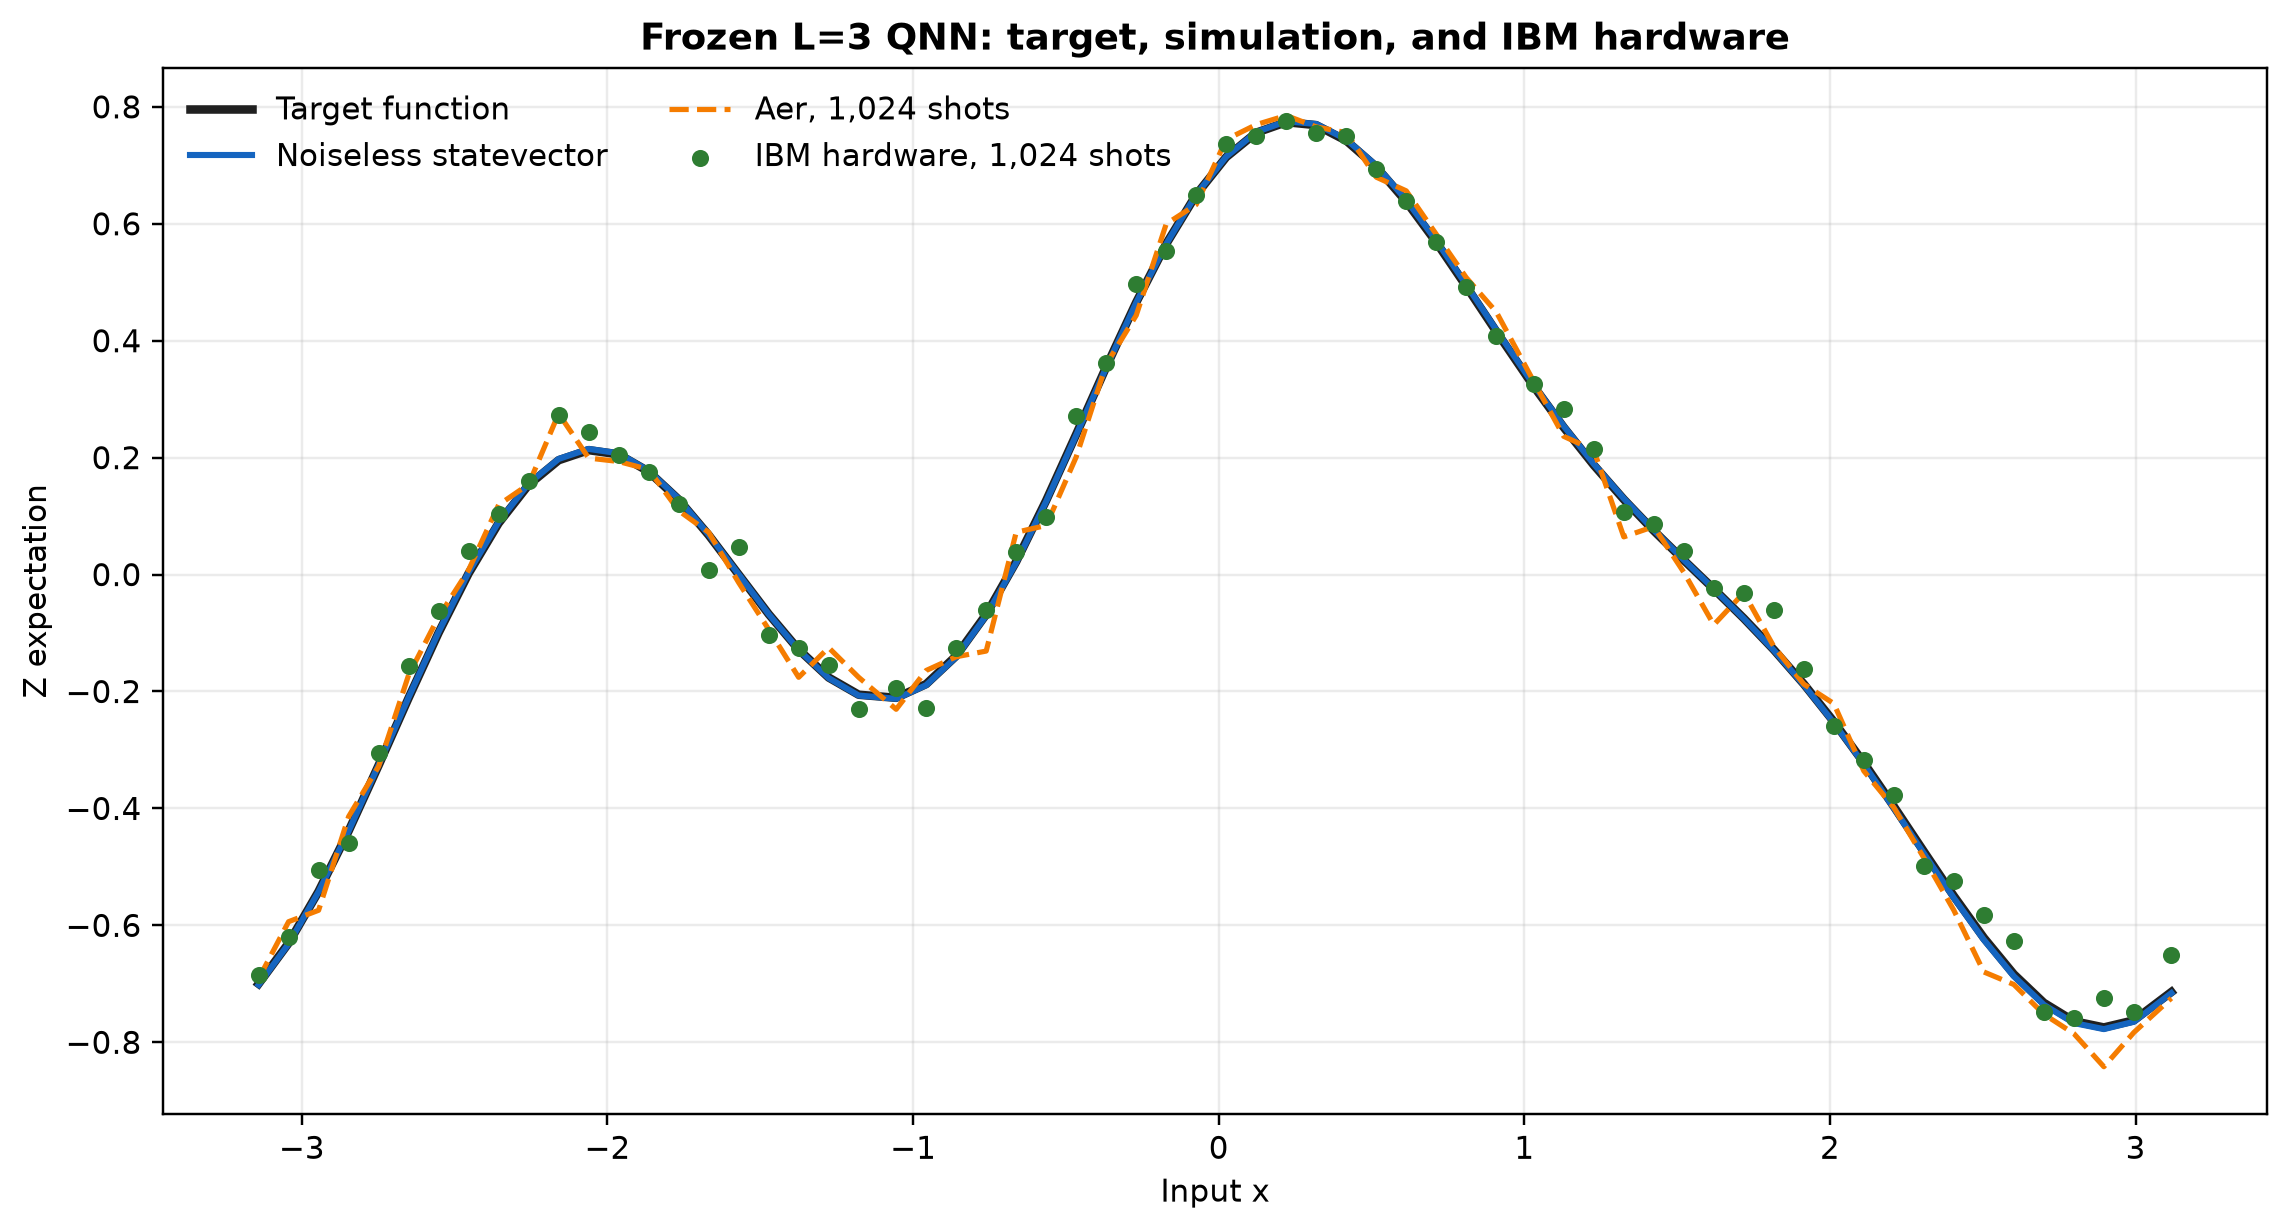

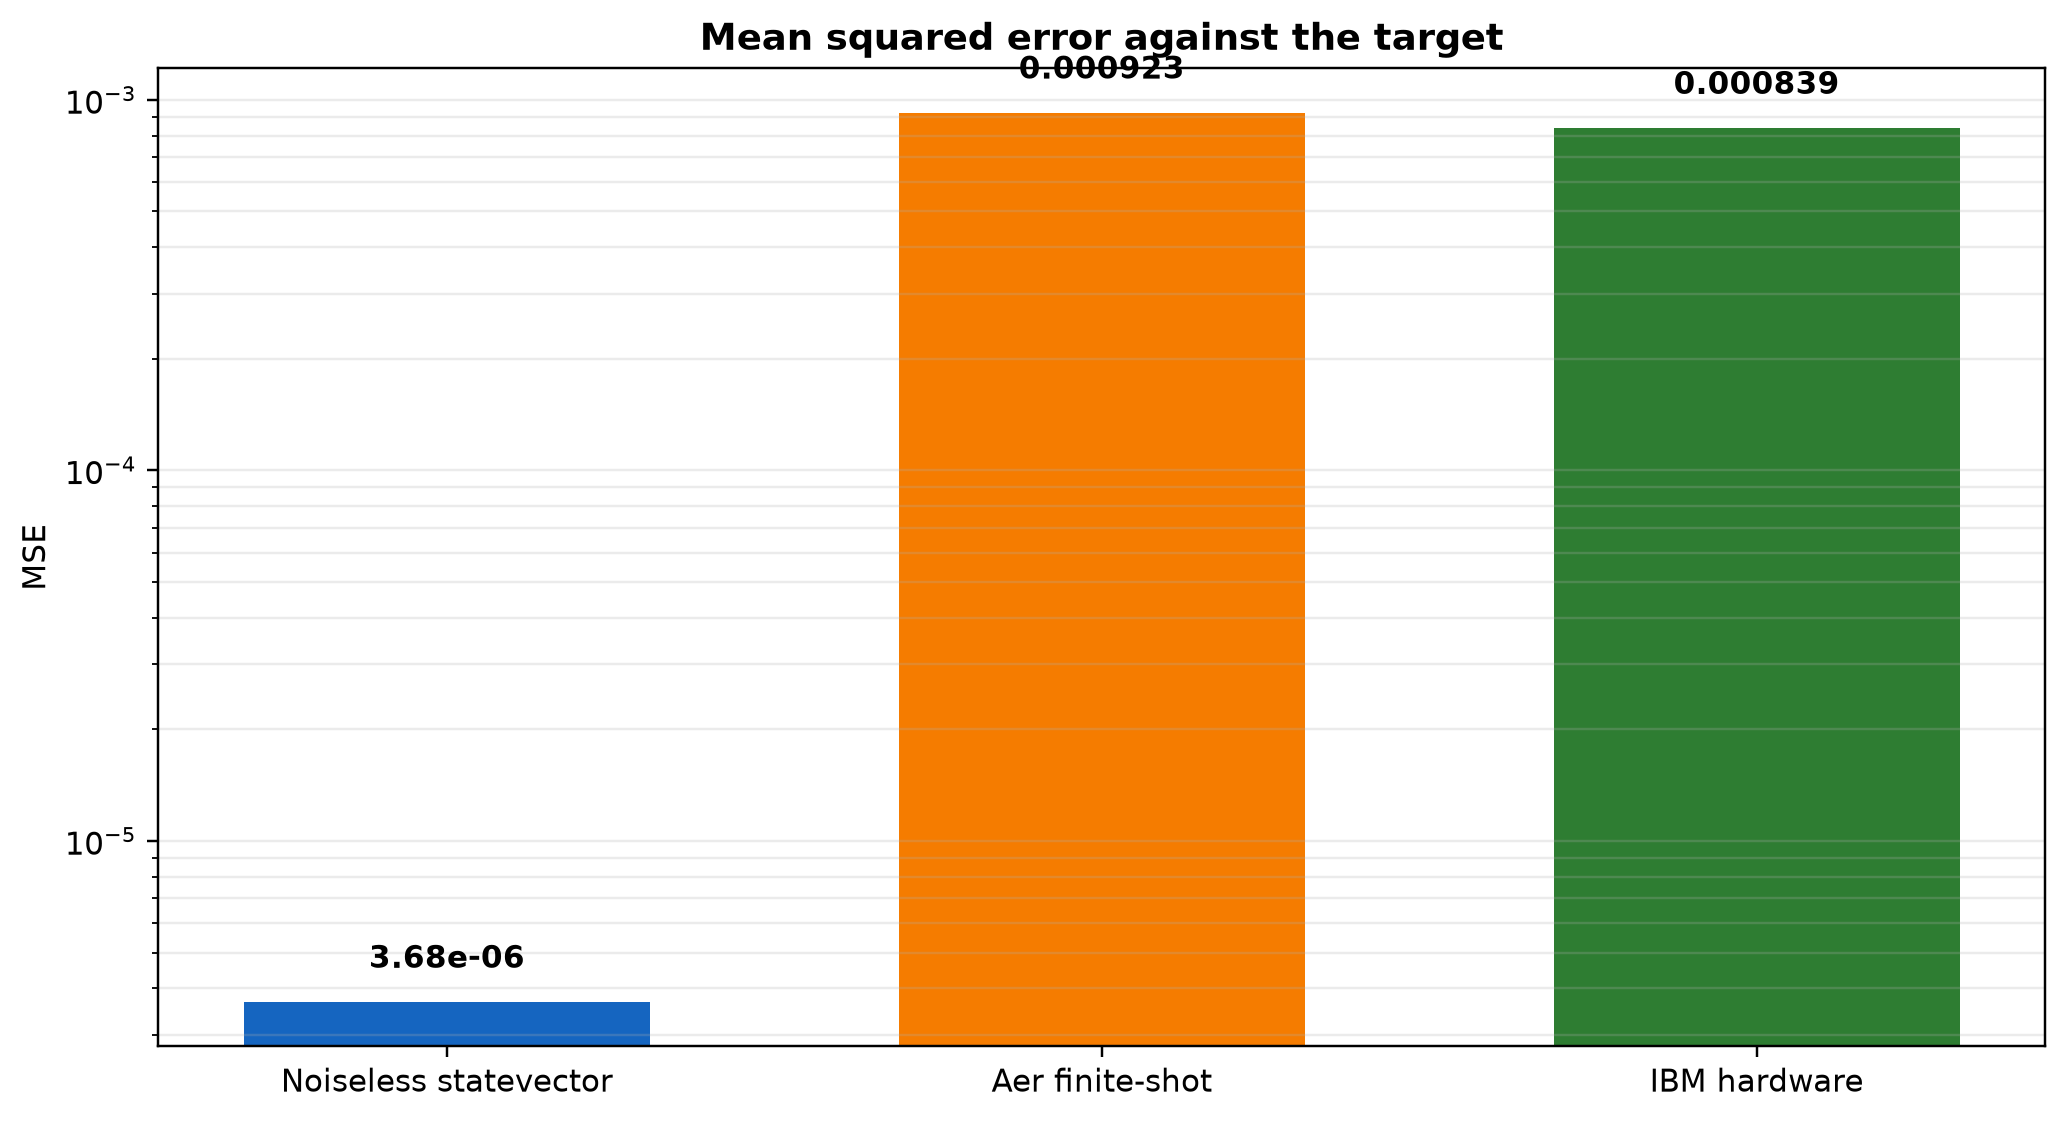

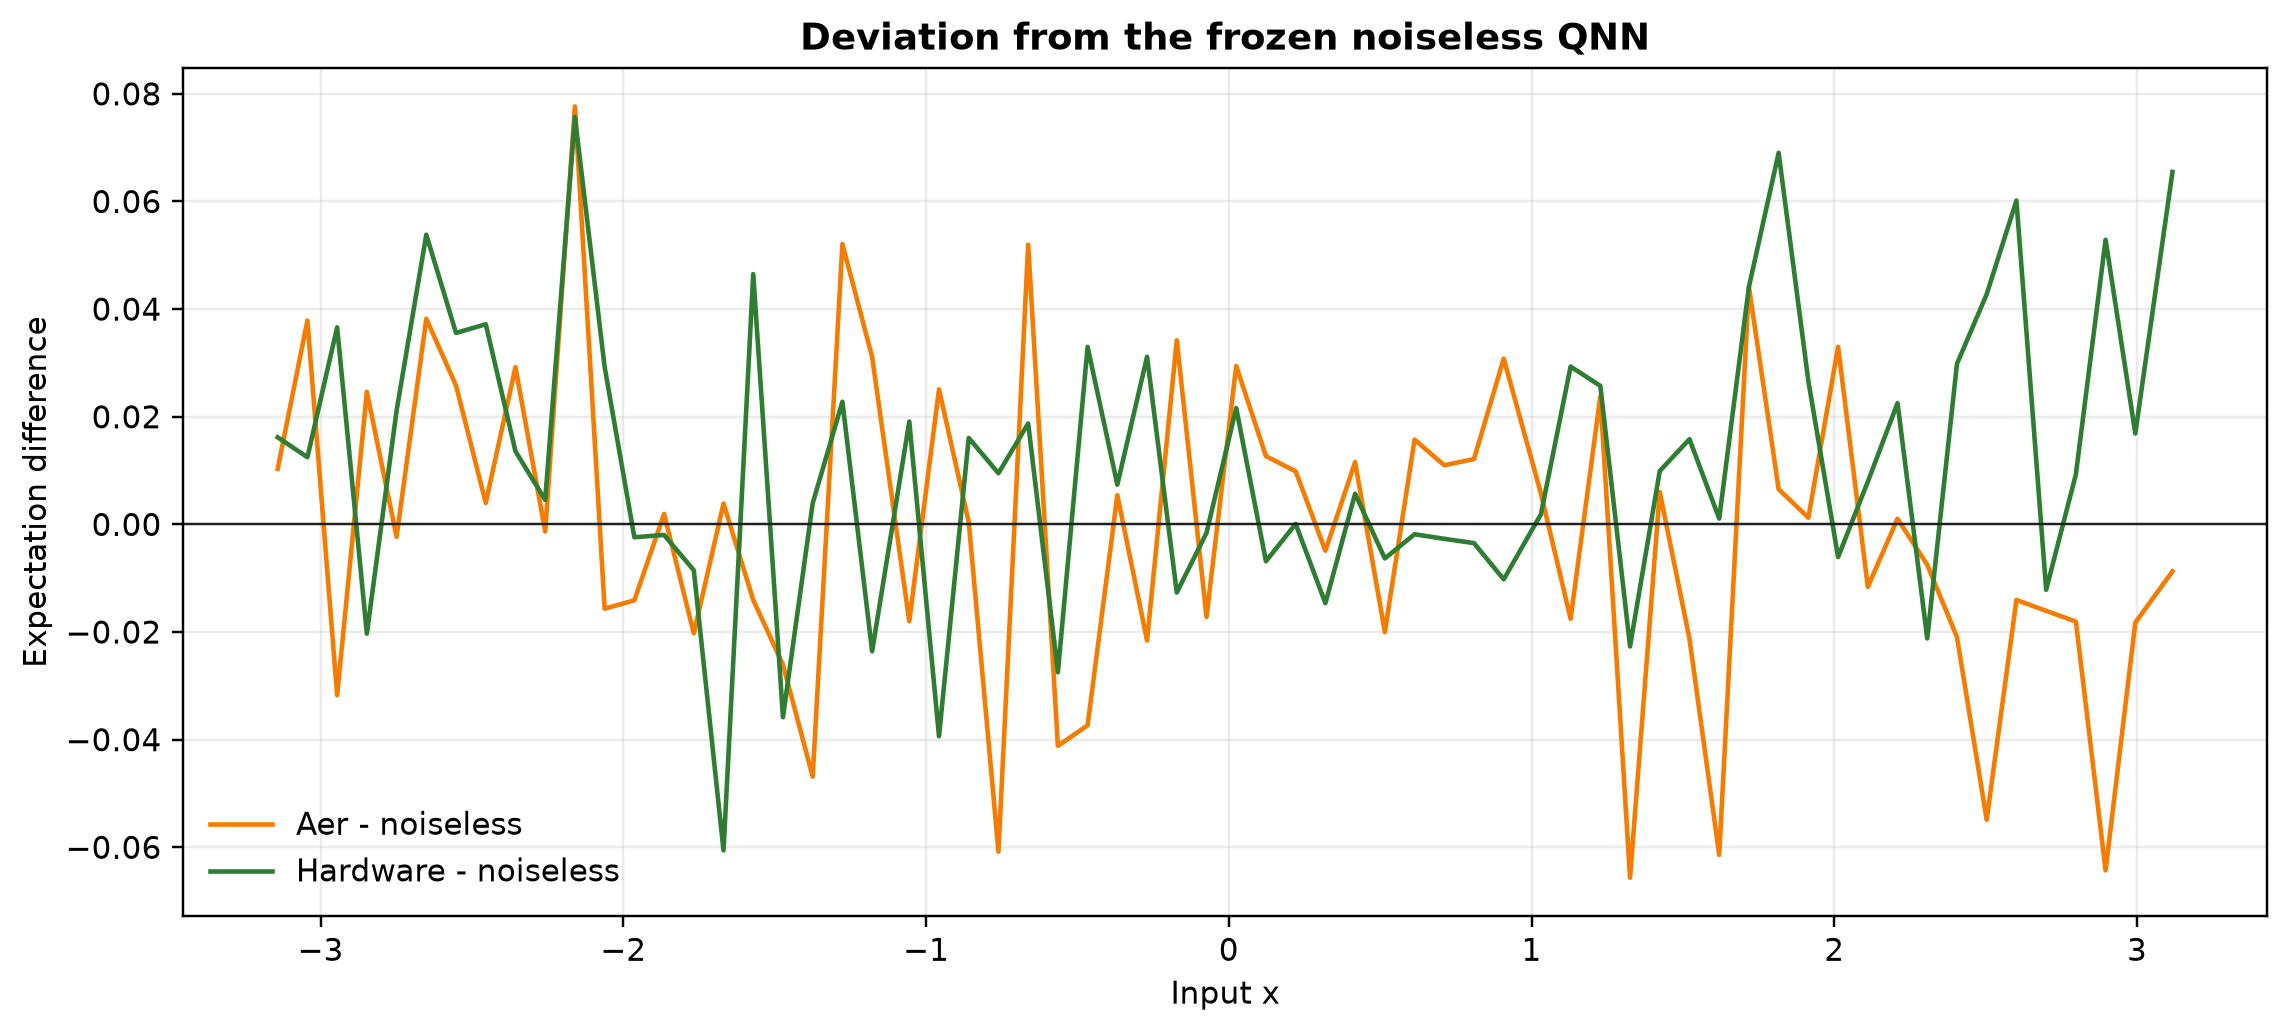

In [4]:
predictions = pd.read_csv(OUT / 'week3_hardware_predictions.csv')
display(predictions.head())
display(Image(filename=str(OUT / 'figures' / 'week3_hardware_curve_comparison.png')))
display(Image(filename=str(OUT / 'figures' / 'week3_error_comparison.png')))
display(Image(filename=str(OUT / 'figures' / 'week3_deviation_from_noiseless.png')))

## Interpretation

The hardware prediction is a noisy measurement of the same frozen circuit. Finite-shot Aer isolates the sampling effect, while the difference between hardware and the noiseless statevector also includes device noise and transpilation effects. Results should be reported as an experiment on this backend, calibration period, circuit, shot count, and set of inputs. They are not a quantum-advantage claim.